# Expirement with running multiple ASP programs multiple times

### Variables

In [67]:
import clingo
import time
import pandas as pd
import matplotlib.pyplot as plt

def load_program(puzzle):
    '''
        Load the necessary lp files to load a complete puzzle:
        - with base file
        - with puzzle world
        - with clues
        and create a clingo control variable
    '''
    ctl = clingo.Control(["0", "--stats=2", "--warn=no-atom-undefined"])
    ctl.load('../solve-experiment.lp')
    ctl.load('../base-rules.lp')
    ctl.load(f'../puzzles/puzzle{puzzle}.lp')
    ctl.load(f'../clues/clues{puzzle}.lp')
    ground_start = time.perf_counter()
    ctl.ground([("base", [])])
    ground_time = time.perf_counter() - ground_start
    return ctl, ground_time
 
def solve_puzzle(puzzle, count=False):
    '''
        Solve a clingo program by loading an lp file.
        Output atoms
        Output all solutions
    '''
    ctl, ground_time = load_program(puzzle)
    def on_model(model):
        print(model.symbols(shown=True))
    with ctl.solve(on_model=on_model, yield_=True) as handle:
        models = list(handle)
        result = handle.get()
        stats = ctl.statistics
        solve_time = stats['summary']['times']['solve']
        grid_size = ctl.get_const('n').number

        # extract number of clues:
        atoms = ctl.symbolic_atoms
        clue_count = sum(1 for atom in atoms if atom.symbol.name == 'clue')
    if count:
        print(f'Number of models: {len(models)}')
        
    print(result)
    print("Satisfiable:", result.satisfiable)
    print("Unsatisfiable:", result.unsatisfiable)
    print("Unknown:", result.unknown)
    return result, ground_time, solve_time, grid_size, clue_count

### Run experiment
- epoch is one run of all available puzzles
- type 'M' puzzles are manually taken from Murdoku book 1
- type 'A' puzzles are automatically generated with our Murdoku-generator
- statistics like grounding time, solving time, total time, grid size and number of clues are store per puzzle per epoch, these can later be used for analysis


In [68]:
# number of runs for experiment
epochs = 5

puzzles = [1,2,8,45]
results = []
for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        print(f'Puzzle #{p}')    
        result, ground_time, solve_time, grid_size, clue_count = solve_puzzle(p)
        results.append({
            'epoch': i,
            'puzzle': p,
            'type': 'M', # TODO: add automated puzzles with 'type': 'A' instead of 'M' for manual
            'ground_time': ground_time,
            'solve_time': solve_time,
            'total_time': ground_time + solve_time,
            'grid_size': grid_size + 1,
            'clue_count': clue_count
        })

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

print('ground times:')
for i in range(epochs):
    print(f'epoch {i+1}:') 
    print(f'ground_times: {[x['ground_time'] for x in results if x['epoch'] == i]}')
    print(f'solve_times: {[x['solve_time'] for x in results if x['epoch'] == i]}')
    print(f'total_times: {[x['total_time'] for x in results if x['epoch'] == i]}')
    print(f'grid_sizes: {[x['grid_size'] for x in results if x['epoch'] == i]}')
    print()

start epoch 1/5
Puzzle #1
[at(alphonse,0,1), at(bonnie,4,0), at(carol,1,2), at(daniel,2,4), at(emily,5,5), at(victor,3,3), murderer(emily), clue(alphonse,on,window), clue(bonnie,in,hallway), clue(carol,on,carpet), clue(daniel,on,bed), clue(emily,next_to,plant)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Puzzle #2
[at(alice,5,1), at(bernard,1,0), at(carol,0,3), at(daniel,2,5), at(edward,3,4), at(victor,4,2), murderer(alice), clue(alice,next_to,tv), clue(bernard,on,chair), clue(carol,in,bathroom), clue(daniel,next_to,plant), clue(daniel,on,bed), clue(edward,next_to,bed)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Puzzle #8
[at(alphonse,5,5), at(bernard,1,4), at(carol,2,6), at(daisy,6,1), at(emily,4,2), at(frank,0,0), at(victoria,3,3), murderer(carol), clue(alphonse,next_to,table), clue(bernard,in_column,4), clue(carol,on,chair), clue(daisy,on,bed), clue(emily,not_next_to,plant), clue(frank,in,backyard), clue(frank,not_next_to,plant)]
SAT
Satisfiable: True
Un

### Analyze
- convert results to Pandas DataFrame for easy evaluation
- Compare performance between puzzles
- Compare performance between grid sizes
- Compare performance between number of clues
- Compare performance between combination of grid size and number of clues

In [69]:
df = pd.DataFrame(results)
df.head()


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count
0,0,1,M,0.042245,0.000121,0.042366,6,5
1,0,2,M,0.023880,0.000238,0.024118,6,6
2,0,8,M,0.048867,0.002112,0.050979,7,7
3,0,45,M,0.246147,0.037670,0.283817,9,12
4,1,1,M,0.021639,0.000096,0.021734,6,5


In [70]:
df.groupby('puzzle')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
puzzle,,,
1,0.025477,0.000103,0.025580
2,0.021240,0.000217,0.021457
8,0.047685,0.002120,0.049805
45,0.245129,0.035571,0.280700


In [71]:
df.groupby('grid_size')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
grid_size,,,
6,0.023358,0.000160,0.023519
7,0.047685,0.002120,0.049805
9,0.245129,0.035571,0.280700


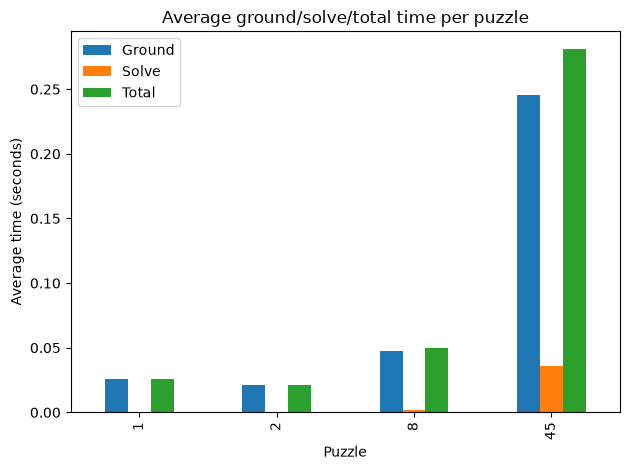

In [72]:
df.groupby('puzzle')[['ground_time','solve_time','total_time']].mean().plot(kind='bar')

plt.xlabel('Puzzle')
plt.ylabel('Average time (seconds)')
plt.title('Average ground/solve/total time per puzzle')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

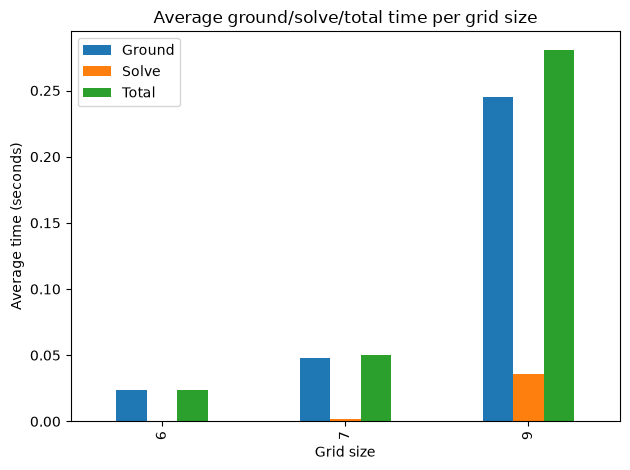

In [73]:
df.groupby('grid_size')[['ground_time','solve_time','total_time']].mean().plot(kind='bar')

plt.xlabel('Grid size')
plt.ylabel('Average time (seconds)')
plt.title('Average ground/solve/total time per grid size')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

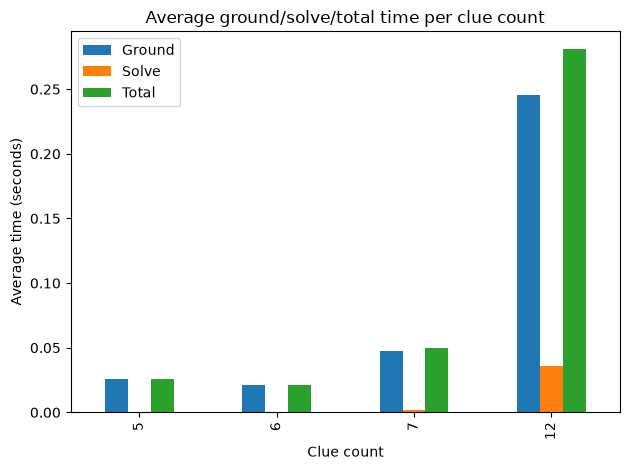

In [75]:
df.groupby('clue_count')[['ground_time','solve_time','total_time']].mean().plot(kind='bar')

plt.xlabel('Clue count')
plt.ylabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()